# IND320 – Project Work Part 4: Machine Learning

**Name:** Alina Shah
**GitHub repository:** https://github.com/59762/IND320-59762 (work is done on the branch `part-4`)
**Streamlit app:** https://ind320-59762.streamlit.app/

## Contents

1. [Setup](#1.-Setup)
2. [Norges Bank exchange rates (EUR and USD)](#2.-Norges-Bank-exchange-rates-(EUR-and-USD))
3. [Timezone investigation](#3.-Timezone-investigation)
4. [Forecasting reservoir filling with River](#4.-Forecasting-reservoir-filling-with-River)
5. [Remaining items for this notebook](#5.-Remaining-items-for-this-notebook)

> **Status of this notebook:** compulsory Jupyter part, step 1 (sections 1-4).
> Testing of many settings, sliding-window findings, the Streamlit sketch, AI usage and the log are added in the next steps (section 5).

## 1. Setup

Run the notebook from top to bottom. It works from the project root or from `notebooks/`.

Extra packages for this part (see `requirements.txt`):
`pip install river geopandas pyogrio shapely`

* Downloaded raw data is cached in `data/cache/` so that repeated runs are fast and reproducible. Add `data/cache/` to `.gitignore`.
* The ENTSO-E token is read from `.streamlit/secrets.toml` (key `entsoe_token`, same as in part 2) or the environment variable `ENTSOE_TOKEN`. It is only needed for the ENTSO-E timezone check in section 3.3, and it is never printed.

In [1]:
# ---- Imports ----------------------------------------------------------------------------
import io
import os
import re
import time
import tomllib
import warnings
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from datetime import date, datetime, timedelta
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

# River = online (streaming) machine learning. Models learn one observation at a time.
from river import forest, linear_model, optim, preprocessing, time_series

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
np.random.seed(42)                                   # reproducible sampling and random forests

# ---- Paths -------------------------------------------------------------------------------
# ROOT = project root, whether the notebook is started from the root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE_DIR = ROOT / "data" / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ---- API endpoints and constants ---------------------------------------------------------
OSLO = "Europe/Oslo"                                 # the one local timezone used in this project
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
OPENMETEO_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
NB_EXR_URL = "https://data.norges-bank.no/api/data/EXR"
ENTSOE_API = "https://web-api.tp.entsoe.eu/api"

print("Project root:", ROOT)
print("Cache folder:", CACHE_DIR)

Project root: c:\Users\Alina\OneDrive - Norwegian University of Life Sciences\NMBU\IND320 - Høst 2026\IND320-59762
Cache folder: c:\Users\Alina\OneDrive - Norwegian University of Life Sciences\NMBU\IND320 - Høst 2026\IND320-59762\data\cache


In [2]:
# ---- Secrets (never print the values) ---------------------------------------------------
def load_secrets(path=None) -> dict:
    # Read .streamlit/secrets.toml if it exists; return {} otherwise
    p = Path(path) if path else ROOT / ".streamlit" / "secrets.toml"
    if p.exists():
        with open(p, "rb") as f:
            return tomllib.load(f)
    return {}


SECRETS = load_secrets()
ENTSOE_TOKEN = SECRETS.get("entsoe_token") or os.getenv("ENTSOE_TOKEN")
print("ENTSO-E token found:", bool(ENTSOE_TOKEN))


# ---- One HTTP helper for all APIs ---------------------------------------------------------
def _redact(text: str) -> str:
    # Remove the ENTSO-E token from error messages (they contain the full URL)
    return re.sub(r"securityToken=[^&\s'\"]+", "securityToken=***", str(text))


def http_get(url, params=None, timeout=60, retries=3, backoff=2.0):
    # GET with retries for temporary errors (timeouts, HTTP 429 and 5xx).
    # Permanent errors (400, 401, 404 ...) fail immediately with a readable message.
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, params=params, timeout=timeout)
        except (requests.ConnectionError, requests.Timeout) as exc:
            last_error = exc
        else:
            if r.status_code == 429 or r.status_code >= 500:
                last_error = f"HTTP {r.status_code}"
            else:
                try:
                    r.raise_for_status()
                except requests.HTTPError as exc:
                    raise RuntimeError(f"HTTP {r.status_code} from {url}: {_redact(exc)}") from None
                return r
        if attempt < retries:
            time.sleep(backoff * attempt)                  # wait a little longer each time
    raise RuntimeError(f"No answer from {url} after {retries} attempts: {_redact(last_error)}")

ENTSO-E token found: True


## 2. Norges Bank exchange rates (EUR and USD)

Norges Bank publishes official exchange rates through an open API:
`https://data.norges-bank.no/api/data/EXR/<key>?format=...&startPeriod=...&endPeriod=...`

The key `B.EUR.NOK.SP` is read as *B* = business-daily frequency, *EUR* = base currency, *NOK* = quote currency,
*SP* = spot. The value is therefore **NOK per 1 EUR** (or per 1 USD).

**Design choices**

* One request per currency. A failing currency is then easy to identify.
* The parser finds the columns by **name** (`BASE_CUR`, `TIME_PERIOD`, `OBS_VALUE`), not by position, and detects `;` or `,` as separator. A changed column order does not break it.
* The function tries `format=csv` (documented by Norges Bank) first and `format=sdmx-csv` as a fallback.
* Rates exist for **business days only**. Two helpers turn them into a gap-free daily series and into the weekly grid of the reservoir data (section 3.5).

In [3]:
def parse_norges_bank_csv(text: str) -> pd.DataFrame:
    # Parse one CSV answer from Norges Bank to a DataFrame indexed by date, one column per currency.
    # Example columns: EURNOK (NOK per 1 EUR).
    first_line = text.lstrip().splitlines()[0]
    sep = ";" if first_line.count(";") > first_line.count(",") else ","
    raw = pd.read_csv(io.StringIO(text), sep=sep)

    # Find the needed columns by name (case-insensitive)
    cols = {c.strip().upper(): c for c in raw.columns}
    time_col = cols.get("TIME_PERIOD") or cols.get("TIME")
    value_col = cols.get("OBS_VALUE")
    cur_col = cols.get("BASE_CUR")
    if not (time_col and value_col and cur_col):
        raise ValueError(f"Unexpected columns from Norges Bank: {list(raw.columns)}")

    out = pd.DataFrame({
        "date": pd.to_datetime(raw[time_col]),
        "cur": raw[cur_col].astype(str).str.upper().str.strip(),
        # decimal comma safety: "11,52" -> 11.52
        "rate": pd.to_numeric(raw[value_col].astype(str).str.replace(",", ".", regex=False),
                              errors="coerce"),
    })
    wide = out.pivot_table(index="date", columns="cur", values="rate", aggfunc="last").sort_index()
    wide.columns = [f"{c}NOK" for c in wide.columns]
    wide.columns.name = None
    return wide


def download_exchange_rates(currencies=("EUR", "USD"), start="2015-01-01", end=None,
                            use_cache=True, max_age_hours=12, timeout=30) -> pd.DataFrame:
    # Download daily (business-day) NOK exchange rates from the Norges Bank API.
    #   currencies : ISO codes, default EUR and USD
    #   start, end : 'YYYY-MM-DD' (end=None means today)
    #   use_cache  : reuse a CSV in data/cache that is younger than max_age_hours
    # Returns a DataFrame indexed by date with columns EURNOK, USDNOK (NOK per 1 unit).
    end = end or date.today().isoformat()
    frames = []
    for cur in currencies:
        cache = CACHE_DIR / f"fx_{cur}_{start}_{end}.csv"
        fresh = cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600
        if use_cache and fresh:
            frames.append(pd.read_csv(cache, index_col=0, parse_dates=True))
            continue

        url = f"{NB_EXR_URL}/B.{cur}.NOK.SP"
        parsed, errors = None, []
        for fmt in ("csv", "sdmx-csv"):                   # documented format first, SDMX as fallback
            params = {"format": fmt, "startPeriod": start, "endPeriod": end, "locale": "en"}
            try:
                parsed = parse_norges_bank_csv(http_get(url, params=params, timeout=timeout).text)
                break
            except Exception as exc:                      # try the next format
                errors.append(f"{fmt}: {exc}")
        if parsed is None or parsed.empty:
            raise RuntimeError(f"Could not download {cur} from Norges Bank. " + " | ".join(errors))
        parsed.to_csv(cache)
        frames.append(parsed)
        time.sleep(0.2)                                   # be polite to the API

    return pd.concat(frames, axis=1).sort_index()

Shape: (2993, 2) | period: 2015-01-02 -> 2026-11-20


,EURNOK,USDNOK
date,,
2015-01-02,9.0420,7.5081
2015-01-05,9.1075,7.6437
2015-01-06,9.1795,7.7048
2015-01-07,9.1500,7.7339
2015-01-08,9.0280,7.6717


,EURNOK,USDNOK
date,,
2026-11-16,10.5740,9.6005
2026-11-17,10.5755,9.6237
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525



All sanity checks passed.

Observations per weekday (expect Monday-Friday only):
date
Monday       586
Tuesday      611
Wednesday    610
Thursday     588
Friday       598
Saturday       0
Sunday         0


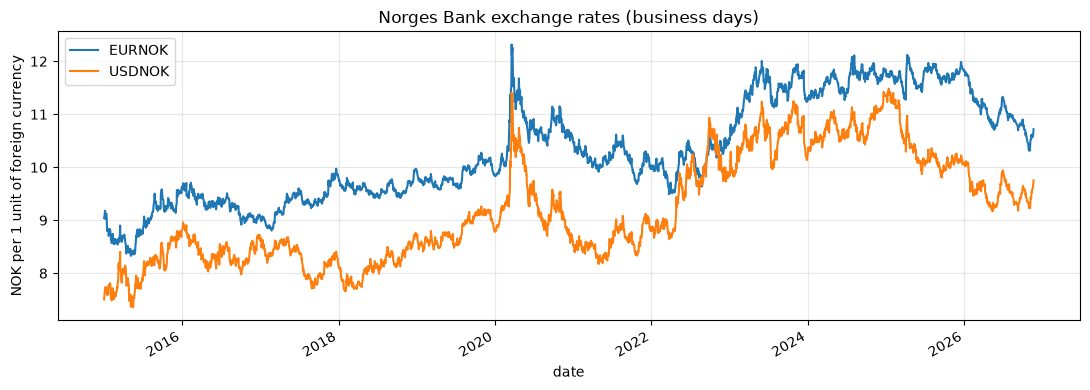

In [4]:
# ---- Test the download function ------------------------------------------------------------
fx = download_exchange_rates(("EUR", "USD"), start="2015-01-01")

print("Shape:", fx.shape, "| period:", fx.index.min().date(), "->", fx.index.max().date())
display(fx.head())
display(fx.tail())

# Sanity checks: fail loudly instead of silently continuing with a bad series
assert {"EURNOK", "USDNOK"} <= set(fx.columns), "a currency column is missing"
assert fx.notna().mean().min() > 0.95, "too many missing values"
assert fx.apply(lambda s: s.between(5, 20)).all().all(), "implausible exchange rates"
print("\nAll sanity checks passed.")

print("\nObservations per weekday (expect Monday-Friday only):")
print(fx.index.day_name().value_counts()
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
      .fillna(0).astype(int).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
fx.plot(ax=ax)
ax.set_ylabel("NOK per 1 unit of foreign currency")
ax.set_title("Norges Bank exchange rates (business days)")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 3. Timezone investigation

**Question:** do Magasinstatistikk (NVE), ENTSO-E, Open-Meteo and Norges Bank describe time in the same way, and what goes wrong if the sources are joined without care?

* **3.1 – 3.4** look at each source with *real API responses* (the cells print what the APIs actually return).
* **3.5** shows what daylight-saving time (DST) does with a controlled example.
* **3.6** defines helper functions that give every source one common time basis.
* **3.7** collects the findings and the rules used in the project.

Norway uses CET (UTC+1) in winter and CEST (UTC+2) in summer. In 2024 the clocks moved on **Sun 31 March** (a 23-hour day) and **Sun 27 October** (a 25-hour day). These two days are used as test cases below.

### 3.1 Magasinstatistikk (NVE)

What to check: does `dato_Id` contain a clock time or an offset, which weekday do the observations fall on, and is the spacing regular? The weekday decides how all other sources must be grouped into weeks.

In [5]:
NVE_RENAME = {
    "dato_Id": "date", "omrType": "area_type", "omrnr": "area_nr", "iso_aar": "year",
    "iso_uke": "week", "fyllingsgrad": "fill_percentage", "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "fill_TWh", "neste_Publiseringsdato": "next_publish_date",
    "fyllingsgrad_forrige_uke": "prev_week_fill_pct", "endring_fyllingsgrad": "change_fill_pct",
}
WEEKDAY_CODE = ["MON", "TUE", "WED", "THU", "FRI", "SAT", "SUN"]     # pandas 'W-<code>' anchors


def load_nve_raw(refresh=False, max_age_hours=24) -> pd.DataFrame:
    # Raw Magasinstatistikk data for all areas, cached as CSV for max_age_hours
    cache = CACHE_DIR / "nve_raw.csv"
    fresh = cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600
    if fresh and not refresh:
        return pd.read_csv(cache)
    df = pd.DataFrame(http_get(f"{NVE_BASE}/HentOffentligData", timeout=60).json())
    df.to_csv(cache, index=False)
    return df


def load_nve_all(refresh=False) -> pd.DataFrame:
    # Cleaned data: English column names, real datetimes, sorted by date
    df = load_nve_raw(refresh).rename(columns=NVE_RENAME)
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)


def detect_nve_anchor(nve: pd.DataFrame) -> str:
    # The weekday on which most observations fall, as a pandas anchor code ('SUN', 'MON', ...)
    return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


nve_raw = load_nve_raw()
nve = load_nve_all()
NVE_ANCHOR = detect_nve_anchor(nve)
no3 = nve[(nve["area_type"] == "EL") & (nve["area_nr"] == 3)]

print("Raw 'dato_Id' examples:         ", nve_raw["dato_Id"].head(3).tolist())
print("Rows:", len(nve), "| area types:", sorted(nve["area_type"].unique()))
print("Any clock time in 'date'?       ", bool(((nve["date"].dt.hour != 0) | (nve["date"].dt.minute != 0)).any()))
print("Observations per weekday:       ", nve["date"].dt.day_name().value_counts().to_dict())
print("Spacing between NO3 rows (days):", no3["date"].diff().dt.days.value_counts().to_dict())
print("=> NVE anchor weekday used in this project:", NVE_ANCHOR)
print("Fill column range (unit check, 0-1 or 0-100):",
      round(float(no3["fill_percentage"].min()), 3), "-", round(float(no3["fill_percentage"].max()), 3))

Raw 'dato_Id' examples:          ['2020-11-15', '2011-08-28', '1998-07-05']
Rows: 14967 | area types: ['EL', 'NO', 'VASS']
Any clock time in 'date'?        False
Observations per weekday:        {'Sunday': 14967}
Spacing between NO3 rows (days): {7.0: 1662}
=> NVE anchor weekday used in this project: SUN
Fill column range (unit check, 0-1 or 0-100): 0.107 - 0.986


C:\Users\Alina\AppData\Local\Temp\ipykernel_3148\3849431921.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


### 3.2 Open-Meteo

The parameter `timezone` decides how Open-Meteo writes its timestamps. The response has **no UTC offset in the timestamps**, so the timezone must be known from the request. The existing `download_weather()` from notebook 3 uses `timezone=Europe/Oslo`, which gives *naive local wall-clock times*. On DST days this is ambiguous: 02:00-03:00 does not exist on 2024-03-31 and happens twice on 2024-10-27.

The test requests the same three-day windows in UTC and in Europe/Oslo, converts the Oslo version to UTC and compares the two. If the conversion is correct, no hours should be missing and no values should differ.

In [6]:
def openmeteo_hourly(lat, lon, start, end, tz, variable="temperature_2m"):
    # One point, one hourly variable. Returns the series (naive index, as sent by the API)
    # and some metadata that the API sends back about the timezone.
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "hourly": variable, "models": "era5", "timezone": tz, "timeformat": "iso8601"}
    j = http_get(OPENMETEO_ARCHIVE, params=params, timeout=30).json()
    s = pd.Series(j["hourly"][variable], index=pd.to_datetime(j["hourly"]["time"]), name=variable)
    meta = {k: j.get(k) for k in ("timezone", "timezone_abbreviation", "utc_offset_seconds")}
    return s, meta


def oslo_naive_to_utc(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    # Convert naive Europe/Oslo wall-clock timestamps to timezone-aware UTC.
    #  - ambiguous='infer' resolves the repeated hour on the fall-back day, but only if the
    #    repeated hour really is present as duplicate rows.
    #  - otherwise the ambiguous hour becomes NaT (it is never silently shifted by one hour).
    #  - non-existent spring-forward times are shifted forward.
    try:
        local = index.tz_localize(OSLO, ambiguous="infer", nonexistent="shift_forward")
    except Exception:
        local = index.tz_localize(OSLO, ambiguous="NaT", nonexistent="shift_forward")
    return local.tz_convert("UTC")


LAT, LON = 63.4, 10.4          # Trondheim area (NO3). Only used for this timezone check.
DST_WINDOWS = {"spring forward (31 Mar 2024)": ("2024-03-30", "2024-04-01"),
               "fall back (27 Oct 2024)":      ("2024-10-26", "2024-10-28")}

rows = []
for label, (d0, d1) in DST_WINDOWS.items():
    s_utc, meta_utc = openmeteo_hourly(LAT, LON, d0, d1, "UTC")
    s_osl, meta_osl = openmeteo_hourly(LAT, LON, d0, d1, OSLO)

    # Oslo request -> UTC, then compare with the UTC request hour by hour
    osl_as_utc = pd.Series(s_osl.values, index=oslo_naive_to_utc(s_osl.index))
    osl_as_utc = osl_as_utc[osl_as_utc.index.notna()]
    osl_as_utc = osl_as_utc[~osl_as_utc.index.duplicated()]
    aligned = osl_as_utc.reindex(s_utc.index.tz_localize("UTC"))
    diff = (aligned.to_numpy() - s_utc.to_numpy())

    expected_oslo_hours = len(pd.date_range(f"{d0} 00:00", f"{d1} 23:00", freq="h", tz=OSLO))
    rows.append({
        "window": label,
        "rows (UTC request)": len(s_utc),
        "rows (Oslo request)": len(s_osl),
        "real hours in the Oslo window": expected_oslo_hours,
        "duplicate Oslo timestamps": int(s_osl.index.duplicated().sum()),
        "hours lost in conversion": int(np.isnan(diff).sum()),
        "values that differ": int((np.abs(diff[~np.isnan(diff)]) > 0.05).sum()),
        "API offset (Oslo req.)": meta_osl["utc_offset_seconds"],
    })

openmeteo_check = pd.DataFrame(rows).set_index("window").T
display(openmeteo_check)

bad = openmeteo_check.loc[["hours lost in conversion", "values that differ"]].to_numpy().sum()
print("Verdict:", "Oslo-time request converts cleanly to UTC." if bad == 0 else
      "Oslo-time request is NOT safe on DST days -> download hourly data with timezone=UTC.")

window,spring forward (31 Mar 2024),fall back (27 Oct 2024)
rows (UTC request),72,72
rows (Oslo request),72,72
real hours in the Oslo window,71,73
duplicate Oslo timestamps,0,0
hours lost in conversion,2,3
values that differ,42,21
API offset (Oslo req.),3600,3600


Verdict: Oslo-time request is NOT safe on DST days -> download hourly data with timezone=UTC.


### 3.3 ENTSO-E

The Transparency Platform API is specified in **UTC**: `periodStart` / `periodEnd` are `yyyyMMddHHmm` in UTC and the time stamps in the XML are UTC (`Z`). The resolution (60 or 15 minutes) is given per `Period` and can differ between documents. The check below downloads the flow NO3 -> SE2 around the October DST change and prints (a) the first returned time stamp against the requested start, (b) the resolutions found, and (c) the number of points per UTC day and per Norwegian calendar day. It is skipped if no token is configured.

The parser is the one from notebook 2.

In [7]:
def resolution_to_minutes(res):
    # ISO 8601 duration used by ENTSO-E, e.g. PT15M, PT30M, PT60M, PT1H
    m = re.fullmatch(r"PT(\d+)([MH])", res.strip())
    if not m:
        raise ValueError(f"Unknown resolution: {res}")
    n, unit = int(m.group(1)), m.group(2)
    return n * 60 if unit == "H" else n


def parse_entsoe_xml(xml_text):
    # Parse an ENTSO-E physical flow XML document into a DataFrame
    # Columns: ts (UTC, timezone-naive), flow_mw, resolution_min.
    # An empty DataFrame is returned for 'no data' (acknowledgement) documents.
    cols = ["ts", "flow_mw", "resolution_min"]
    root = ET.fromstring(xml_text)
    ns = root.tag[1:root.tag.index("}")] if root.tag.startswith("{") else ""
    q = (lambda name: f"{{{ns}}}{name}") if ns else (lambda name: name)

    rows = []
    for series in root.iter(q("TimeSeries")):
        curve_type = series.findtext(q("curveType"))          # A01 = every point, A03 = only changes
        for period in series.findall(q("Period")):
            ti = period.find(q("timeInterval"))
            start = datetime.fromisoformat(ti.findtext(q("start")).replace("Z", "+00:00"))
            end = datetime.fromisoformat(ti.findtext(q("end")).replace("Z", "+00:00"))
            res = resolution_to_minutes(period.findtext(q("resolution")))
            step = timedelta(minutes=res)
            n_slots = int((end - start) / step)

            # position -> quantity as given in the XML
            values = {
                int(pt.findtext(q("position"))): float(pt.findtext(q("quantity")))
                for pt in period.findall(q("Point"))
            }

            last = None
            for pos in range(1, n_slots + 1):
                if pos in values:
                    last = values[pos]
                elif curve_type != "A03":
                    continue                                   # a real gap: leave it missing
                if last is None:
                    continue
                rows.append((start + (pos - 1) * step, last, res))

    if not rows:
        return pd.DataFrame(columns=cols)
    out = pd.DataFrame(rows, columns=cols)
    out["ts"] = pd.to_datetime(out["ts"]).dt.tz_convert("UTC").dt.tz_localize(None)   # naive UTC
    return out.drop_duplicates("ts").sort_values("ts").reset_index(drop=True)


EIC = {"NO3": "10YNO-3--------J", "SE2": "10Y1001A1001A45N"}        # same EIC codes as in notebook 2


def fetch_entsoe_flow_window(out_zone, in_zone, start_utc, end_utc):
    # Physical flow (documentType A11) between two zones; start/end are naive UTC datetimes
    params = {"securityToken": ENTSOE_TOKEN, "documentType": "A11",
              "out_Domain": EIC[out_zone], "in_Domain": EIC[in_zone],
              "periodStart": start_utc.strftime("%Y%m%d%H%M"),
              "periodEnd": end_utc.strftime("%Y%m%d%H%M")}
    return parse_entsoe_xml(http_get(ENTSOE_API, params=params, timeout=90).text)


entsoe_check = None
if not ENTSOE_TOKEN:
    print("No ENTSO-E token found -> check skipped. Add 'entsoe_token' to .streamlit/secrets.toml to run it.")
else:
    # Window = four complete NORWEGIAN days (25-28 Oct 2024), expressed in UTC for the request
    start_utc = pd.Timestamp("2024-10-25 00:00", tz=OSLO).tz_convert("UTC").tz_localize(None)   # 2024-10-24 22:00
    end_utc = pd.Timestamp("2024-10-29 00:00", tz=OSLO).tz_convert("UTC").tz_localize(None)     # 2024-10-28 23:00
    flow = fetch_entsoe_flow_window("NO3", "SE2", start_utc.to_pydatetime(), end_utc.to_pydatetime())
    if flow.empty:
        print("ENTSO-E returned no data for this window.")
    else:
        flow_utc = flow.set_index(flow["ts"].dt.tz_localize("UTC"))["flow_mw"]
        points_per_hour = 60 // int(flow["resolution_min"].mode().iloc[0])
        per_oslo_day = flow_utc.tz_convert(OSLO).groupby(flow_utc.tz_convert(OSLO).index.date).size()
        entsoe_check = pd.DataFrame({"points": per_oslo_day, "hours": per_oslo_day / points_per_hour})
        print("Requested start (UTC):          ", start_utc, "(= Norwegian midnight)")
        print("First returned timestamp (UTC): ", flow["ts"].min())
        print("Resolutions found (minutes):    ", flow["resolution_min"].value_counts().to_dict())
        print("Duplicate timestamps:           ", int(flow["ts"].duplicated().sum()))
        display(entsoe_check.rename_axis("Norwegian day"))
        h27 = entsoe_check.loc[date(2024, 10, 27), "hours"]
        print("Verdict:", "27 Oct has 25 hours as expected." if h27 == 25 else
              f"27 Oct has {h27} hours - the API data does not follow the 25-hour Norwegian day, investigate.")

Requested start (UTC):           2024-10-24 22:00:00 (= Norwegian midnight)
First returned timestamp (UTC):  2024-10-24 22:00:00
Resolutions found (minutes):     {60: 97}
Duplicate timestamps:            0


,points,hours
Norwegian day,,
2024-10-25,24,24.0
2024-10-26,24,24.0
2024-10-27,25,25.0
2024-10-28,24,24.0


Verdict: 27 Oct has 25 hours as expected.


### 3.4 Norges Bank

The date has **no clock time**. Rates are only published for Norwegian banking days (no weekends or public holidays), and each rate is a fixing at one time of the day, so no timezone conversion is needed - but the series has gaps. The check uses the data downloaded in section 2.

In [8]:
idx = fx.index.to_series()
gap_days = idx.diff().dt.days
print("[Norges Bank] clock time in the index?   ", bool((fx.index.hour != 0).any()))
print("[Norges Bank] weekend observations:      ", int((fx.index.dayofweek >= 5).sum()))
print("[Norges Bank] gap between rows (days -> count):", gap_days.value_counts().sort_index().to_dict())

print("\nLongest gaps (public holidays such as Easter and Christmas):")
display(gap_days.nlargest(5).rename("gap_days").to_frame().assign(ends_on=lambda d: d.index.date))

[Norges Bank] clock time in the index?    False
[Norges Bank] weekend observations:       0
[Norges Bank] gap between rows (days -> count): {1.0: 2347, 2.0: 22, 3.0: 577, 4.0: 26, 5.0: 6, 6.0: 14}

Longest gaps (public holidays such as Easter and Christmas):


C:\Users\Alina\AppData\Local\Temp\ipykernel_3148\3401863264.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  print("[Norges Bank] weekend observations:      ", int((fx.index.dayofweek >= 5).sum()))


,gap_days,ends_on
date,,
2015-04-07,6.0,2015-04-07
2016-03-29,6.0,2016-03-29
2017-04-18,6.0,2017-04-18
2018-04-03,6.0,2018-04-03
2018-12-27,6.0,2018-12-27


### 3.5 What can go wrong: a DST demonstration

DST only matters for sources with an **hourly clock time** (ENTSO-E, Open-Meteo). The demo uses a constant flow of 1 MW over the October 2024 DST change and sums it per day:

* grouping by **UTC date** gives 24 MWh every day, but those days do not match the Norwegian calendar day;
* grouping by **Oslo date** gives 25 MWh on 2024-10-27, which is physically correct.

Joining a "daily" Oslo-based series (e.g. weather with `timezone=Europe/Oslo`) with a daily series grouped by UTC date (e.g. ENTSO-E in part 2) therefore shifts one of them by 1-2 hours. The same applies to the **year boundary**: Oslo 1 January 00:00 is 31 December 23:00 UTC, so a "year" defined in UTC (as the Cassandra partition key in part 2) is one hour off the Norwegian year.

In [9]:
hours_utc = pd.date_range("2024-10-25 00:00", "2024-10-29 23:00", freq="h", tz="UTC")
demo = pd.Series(1.0, index=hours_utc, name="MWh")            # constant 1 MW -> 1 MWh per hour

by_utc = demo.resample("D").sum()                               # UTC calendar days
by_oslo = demo.tz_convert(OSLO).resample("D").sum()             # Norwegian calendar days (DST-aware)
by_utc.index, by_oslo.index = by_utc.index.tz_localize(None), by_oslo.index.tz_localize(None)

display(pd.concat([by_utc.rename("sum per UTC day"), by_oslo.rename("sum per Oslo day")], axis=1))
assert by_oslo.loc["2024-10-27"] == 25 and by_utc.loc["2024-10-27"] == 24
print("OK: the fall-back day has 25 hours in Oslo time but 24 in UTC.")

# Year boundary: how many hours of Norwegian 1 January fall into the UTC year before?
new_year_oslo = pd.Timestamp("2025-01-01 00:00", tz=OSLO)
print("Norwegian New Year 2025 in UTC:", new_year_oslo.tz_convert("UTC"))

,sum per UTC day,sum per Oslo day
2024-10-25,24.0,22.0
2024-10-26,24.0,24.0
2024-10-27,24.0,25.0
2024-10-28,24.0,24.0
2024-10-29,24.0,24.0
2024-10-30,NaN,1.0


OK: the fall-back day has 25 hours in Oslo time but 24 in UTC.
Norwegian New Year 2025 in UTC: 2024-12-31 23:00:00+00:00


### 3.6 Solution: one common time basis

**Procedure used for every source in the project**

1. Make every hourly index **timezone-aware UTC** (`hourly_to_utc`).
2. Convert to `Europe/Oslo` with `tz_convert` **only when grouping** into days or weeks.
3. Aggregate to the NVE weekly grid, `W-<anchor>`, labelled by the week-ending date (`utc_to_weekly`, `daily_to_weekly`).
4. Join on the date index. Use **sums** for energy and precipitation and **means** for power, temperature and rates.

In [10]:
def hourly_to_utc(df: pd.DataFrame, source: str) -> pd.DataFrame:
    # Return df with a timezone-aware UTC index. `source` tells how the incoming index must be read:
    #   'entsoe'          naive index is already UTC
    #   'openmeteo_utc'   naive index is UTC (requested with timezone=UTC)
    #   'openmeteo_oslo'  naive index is Europe/Oslo wall-clock time (requested with timezone=Europe/Oslo)
    out = df.copy()
    if source in ("entsoe", "openmeteo_utc"):
        out.index = pd.DatetimeIndex(out.index).tz_localize("UTC")
    elif source == "openmeteo_oslo":
        out.index = oslo_naive_to_utc(pd.DatetimeIndex(out.index))
        out = out[out.index.notna()]                         # drop hours that cannot be resolved
    else:
        raise ValueError(f"Unknown source {source!r}")
    return out.sort_index()


def utc_to_weekly(df_utc: pd.DataFrame, anchor: str = None, agg="mean") -> pd.DataFrame:
    # Aggregate a timezone-aware UTC hourly frame to the NVE week grid using Norwegian calendar days.
    #   agg: 'mean' | 'sum' | {column: 'mean'|'sum'}
    anchor = anchor or NVE_ANCHOR
    res = df_utc.tz_convert(OSLO).resample(f"W-{anchor}")    # weeks end at Oslo midnight, DST-safe
    out = res.agg(agg) if isinstance(agg, dict) else getattr(res, agg)()
    out.index = out.index.tz_localize(None).normalize()      # label = week-ending date, like NVE
    return out


def daily_to_weekly(df_daily: pd.DataFrame, anchor: str = None, agg="mean") -> pd.DataFrame:
    # Aggregate a DAILY frame with a naive date index to the NVE week grid.
    # The last week is dropped if it is not complete (its label is after the last available day).
    anchor = anchor or NVE_ANCHOR
    res = df_daily.resample(f"W-{anchor}")
    out = res.agg(agg) if isinstance(agg, dict) else getattr(res, agg)()
    return out[out.index <= df_daily.index.max()]


# ---- Test the helpers on a synthetic example ------------------------------------------------
hours = pd.date_range("2024-10-01", "2024-11-10 23:00", freq="h", tz="UTC")
toy = pd.DataFrame({"MW": 1.0}, index=hours.tz_localize(None))
toy_w = utc_to_weekly(hourly_to_utc(toy, "entsoe"), anchor="SUN", agg="sum")
print("Toy weekly sums (MWh). A normal week has 168 h; the week with the DST change has 169 h:")
print(toy_w.loc["2024-10-20":"2024-11-03", "MW"].to_string())
assert toy_w.loc["2024-10-27", "MW"] == 169, "week ending 2024-10-27 should contain 169 h"

# Effect of ignoring the timezone: grouping a weekly sum by UTC dates instead of Oslo dates
naive_w = toy.resample("W-SUN").sum()
print("\nWeek ending 2024-10-27 -> UTC grouping:", naive_w.loc["2024-10-27", "MW"],
      "h, Oslo grouping:", toy_w.loc["2024-10-27", "MW"], "h")

Toy weekly sums (MWh). A normal week has 168 h; the week with the DST change has 169 h:
2024-10-20    168.0
2024-10-27    169.0
2024-11-03    168.0
Freq: W-SUN

Week ending 2024-10-27 -> UTC grouping: 168.0 h, Oslo grouping: 169.0 h


### 3.7 Findings and rules

| Source | Native time reference | Resolution | Rule used when joining |
|---|---|---|---|
| **Magasinstatistikk (NVE)** | Date only, no clock time, no offset. Observations lie on one weekday (see `NVE_ANCHOR` printed in 3.1). | Weekly | Defines the **target grid** `W-<anchor>`. Nothing to convert. |
| **ENTSO-E** | **UTC** in the request (`periodStart`/`periodEnd`) and in the response (`Z`). | 60 or 15 min, set per document | Keep as timezone-aware UTC. Convert to Europe/Oslo only for grouping into days/weeks. Do **not** use UTC years/days as Norwegian calendar periods. |
| **Open-Meteo** | Whatever `timezone=` says (default GMT). Timestamps have **no offset**, so the request must be remembered. | Hourly or daily | Hourly data: request `timezone=UTC`. Daily data: request `Europe/Oslo` so that a day is a Norwegian day (daily values have no DST ambiguity). |
| **Norges Bank** | Date only. One fixing per Norwegian banking day. | Daily, no weekends/holidays | Forward-fill to calendar days, then average per week. No timezone conversion needed. |

**Practical consequences**

* The four sources are only really "in different timezones" for the two **hourly** sources; NVE and Norges Bank carry dates only. The mismatch that matters is the *definition of the day/week*: UTC day vs Norwegian day vs the NVE weekday.
* On DST days Norwegian days have 23 or 25 hours. Summing hourly energy per UTC day or per Oslo day gives different numbers; only Oslo-day sums are correct for Norwegian calendar periods (demo in 3.5, week check in 3.6).
* The forecasting below works on **weekly** data. Weather is downloaded as **daily** values with `timezone=Europe/Oslo`, currency is forward-filled from business days, and both are averaged/summed on the NVE week grid with `daily_to_weekly`.
* Open-Meteo's ERA5 archive lags a few days behind today, so the newest days are missing. Missing future weather is replaced by climatology in the forecast function (section 4).

> After running this section on your computer, check the printed tables in 3.1-3.4 against the table above and adjust any sentence where the real output differs (for example the observation weekday or the ENTSO-E resolution).

## 4. Forecasting reservoir filling with River

**Goal:** one function, `forecast_fill()`, that forecasts the coming weeks/months of reservoir filling for **a single Magasinstatistikk area** and lets the caller choose the **model parameters, the length of the history, the forecast horizon and the data sources**.

### 4.1 Design decisions

| Decision | Choice | Reason |
|---|---|---|
| Framework | [River](https://riverml.xyz) online learning | Required by the assignment. A model learns one observation at a time (`learn_one`) and forecasts recursively. |
| Models | `"snarimax"` = `river.time_series.SNARIMAX` (the SARIMAX equivalent) and `"lag_ml"` = own lag features + any River regressor | SNARIMAX covers the SARIMAX requirement, `lag_ml` is the lag-based machine-learning option and also allows a non-linear regressor (random forest). |
| Time resolution | **Weekly** (native NVE resolution, seasonal period 52). Monthly (period 12) is available through `resolution="M"` for comparison | The target only exists weekly. Daily data would mean inventing the target between observations and a seasonal period of 365. Weekly keeps training in a fraction of a second. Section 5 compares the two. |
| Data sources | Target = Magasinstatistikk fill. Optional exogenous variables from **weather** (Open-Meteo), **currency** (Norges Bank) or any extra weekly DataFrame (e.g. ENTSO-E flows) | They are passed as a dict `exog = {source: DataFrame}` and selected with `exog_vars`. |
| Lagged exogenous data | `exog_lags`, e.g. `(0, 4, 8)` | Weather affects reservoirs with a delay (snow melt, inflow). |
| Future exogenous values | Unknown when forecasting. Weather -> **climatology** (mean of the same week in earlier years); currency -> **last known value** | No data from after `train_end` is ever used, so the same code can be backtested without leakage. |
| Target scaling | The target is standardised (z-score) inside the function and transformed back | SGD-trained models are sensitive to the scale of the target. |
| Confidence interval (bonus) | `interval=True` trains two extra models with `optim.losses.Quantile` | Required by the bonus task "Confidence intervals in SARIMAX". |

### 4.2 Data for one area: target, weather and currency

* `make_fill_series` puts the fill percentage of one area on the weekly NVE grid.
* `sample_points` picks random points inside the real area polygon (shapefiles from part 3) so the weather represents the whole area.
* `fetch_weather_daily` downloads **daily** ERA5 data with `timezone=Europe/Oslo` (see section 3: daily values have no DST ambiguity) and averages over the points.
* `build_exog_sources` converts everything to the weekly grid.

In [11]:
# ---- Target: weekly fill series of one area -------------------------------------------------
def make_fill_series(nve: pd.DataFrame, area_type="EL", area_nr=3, anchor=None,
                     col="fill_percentage") -> pd.Series:
    # Weekly series on the NVE grid (W-<anchor>, label = week-ending date).
    anchor = anchor or NVE_ANCHOR
    sel = nve[(nve["area_type"] == area_type) & (nve["area_nr"] == area_nr)]
    if sel.empty:
        have = sorted(nve.groupby(["area_type", "area_nr"]).size().index.tolist())
        raise ValueError(f"No data for {area_type} {area_nr}. Available areas: {have}")
    s = sel.set_index("date")[col].astype(float).sort_index()
    s = s[~s.index.duplicated(keep="last")]
    weekly = s.resample(f"W-{anchor}").last()
    weekly = weekly.interpolate(limit=3, limit_area="inside")      # fill short holes only
    weekly = weekly.dropna()
    weekly.name = f"{area_type}{area_nr}"
    return weekly


# ---- Weather: sample points inside the area polygon -----------------------------------------
import geopandas as gpd
import shapely

SHAPE_DIR = ROOT / "data" / "shapefiles"
EL_AREAS = gpd.read_file(next((SHAPE_DIR / "electricity_areas").glob("*.shp"))).to_crs("EPSG:25833")
NVE_REGIONS = gpd.read_file(next((SHAPE_DIR / "NVE_Regions").glob("*.shp")), encoding="utf-8").to_crs("EPSG:25833")
VASS_WEST, VASS_NORTH = ["RV"], ["RM", "RN"]           # VASS1 = rest (RS + RØ), VASS2 = RV, VASS3 = RM + RN


@lru_cache(maxsize=None)
def area_polygon(area_type: str, area_nr: int):
    # Polygon (EPSG:25833, metres) of one NVE area. Same mapping as in notebook 3.
    if area_type == "EL":
        nr = EL_AREAS["budomr"].astype(str).str.extract(r"(\d+)")[0].astype(float)
        sel = EL_AREAS[nr == area_nr]
    elif area_type == "VASS":
        code_ = NVE_REGIONS["REGION"]
        masks = {1: ~code_.isin(VASS_WEST + VASS_NORTH), 2: code_.isin(VASS_WEST), 3: code_.isin(VASS_NORTH)}
        if area_nr not in masks:
            raise ValueError("VASS area must be 1, 2 or 3")
        sel = NVE_REGIONS[masks[area_nr]]
    else:
        raise ValueError(f"No polygon for area_type={area_type!r} (use 'EL' or 'VASS')")
    if sel.empty:
        raise ValueError(f"No polygon found for {area_type} {area_nr}")
    return shapely.union_all(sel.geometry.values)


def sample_points(area_type: str, area_nr: int, n: int = 10, seed: int = 42) -> list:
    # n random (lat, lon) points inside the area (rejection sampling, reproducible via seed)
    geom = area_polygon(area_type, area_nr)
    rng = np.random.default_rng(seed)
    minx, miny, maxx, maxy = geom.bounds
    xs, ys = [], []
    while len(xs) < n:
        x, y = rng.uniform(minx, maxx, 500), rng.uniform(miny, maxy, 500)
        ok = shapely.contains_xy(geom, x, y)
        xs += x[ok].tolist()
        ys += y[ok].tolist()
    pts = gpd.GeoSeries(gpd.points_from_xy(xs[:n], ys[:n]), crs="EPSG:25833").to_crs("EPSG:4326")
    return [(p.y, p.x) for p in pts]                     # (lat, lon)

In [12]:
# ---- Weather: daily ERA5 data from Open-Meteo ----------------------------------------------
# API variable -> (short name, how to aggregate days to a week)
WEATHER_DAILY = {
    "temperature_2m_mean": ("temperature", "mean"),
    "precipitation_sum":   ("precipitation", "sum"),
    "snowfall_sum":        ("snowfall", "sum"),
    "wind_speed_10m_max":  ("wind", "mean"),
}
WEATHER_AGG = {name: how for name, how in WEATHER_DAILY.values()}


def fetch_weather_daily(points, start: str, end: str, chunk: int = 10) -> pd.DataFrame:
    # Regional mean of daily weather over several (lat, lon) points.
    # Open-Meteo accepts several coordinates per request; `chunk` limits how many per call.
    per_point = []
    for i in range(0, len(points), chunk):
        pts = points[i:i + chunk]
        params = {
            "latitude": ",".join(f"{lat:.4f}" for lat, _ in pts),
            "longitude": ",".join(f"{lon:.4f}" for _, lon in pts),
            "start_date": start, "end_date": end,
            "daily": ",".join(WEATHER_DAILY), "models": "era5",
            "timezone": OSLO,                              # a 'day' is a Norwegian day (see section 3)
        }
        data = http_get(OPENMETEO_ARCHIVE, params=params, timeout=90).json()
        for loc in (data if isinstance(data, list) else [data]):   # a list when there are >1 coordinates
            d = pd.DataFrame(loc["daily"])
            d["time"] = pd.to_datetime(d["time"])
            per_point.append(d.set_index("time"))
        time.sleep(0.5)                                    # be polite to the free API
    daily = pd.concat(per_point).groupby(level=0).mean()   # mean over all points, per day
    return daily.rename(columns={k: v[0] for k, v in WEATHER_DAILY.items()}).sort_index()


def fetch_weather_cached(area_type, area_nr, start, end, n_points=10, max_age_hours=24) -> pd.DataFrame:
    # Same as fetch_weather_daily for one area, with a CSV cache in data/cache
    cache = CACHE_DIR / f"weather_{area_type}{area_nr}_{start}_{end}_{n_points}pts.csv"
    if cache.exists() and (time.time() - cache.stat().st_mtime) < max_age_hours * 3600:
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    daily = fetch_weather_daily(sample_points(area_type, area_nr, n_points), start, end)
    daily.to_csv(cache)
    return daily


def build_exog_sources(area_type="EL", area_nr=3, start="2010-01-01", end=None, anchor=None,
                       n_points=10, sources=("weather", "currency")) -> dict:
    # Weekly exogenous data on the NVE grid: {'weather': DataFrame, 'currency': DataFrame}
    anchor = anchor or NVE_ANCHOR
    # ERA5 is published with a delay of a few days -> do not ask for the very latest days
    end = end or (date.today() - timedelta(days=6)).isoformat()
    out = {}
    if "weather" in sources:
        daily = fetch_weather_cached(area_type, area_nr, start, end, n_points)
        out["weather"] = daily_to_weekly(daily, anchor, WEATHER_AGG)
    if "currency" in sources:
        fx_b = download_exchange_rates(("EUR", "USD"), start=start, end=end)
        full_days = pd.date_range(fx_b.index.min(), pd.Timestamp(end))       # business days -> every day
        out["currency"] = daily_to_weekly(fx_b.reindex(full_days).ffill(), anchor, "mean")
    return out

C:\Users\Alina\AppData\Local\Temp\ipykernel_3148\3849431921.py:30: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  return WEEKDAY_CODE[int(nve["date"].dt.dayofweek.mode().iloc[0])]


Target EL3: 1663 weekly values, 1995-01-08 -> 2026-11-15
Value range (shows the unit, 0-1 or 0-100): 0.107 - 0.986
Exog 'weather': (881, 4), 2010-01-03 -> 2026-11-15, columns ['temperature', 'precipitation', 'snowfall', 'wind'], NaN share 0.000
Exog 'currency': (880, 2), 2010-01-10 -> 2026-11-15, columns ['EURNOK', 'USDNOK'], NaN share 0.000


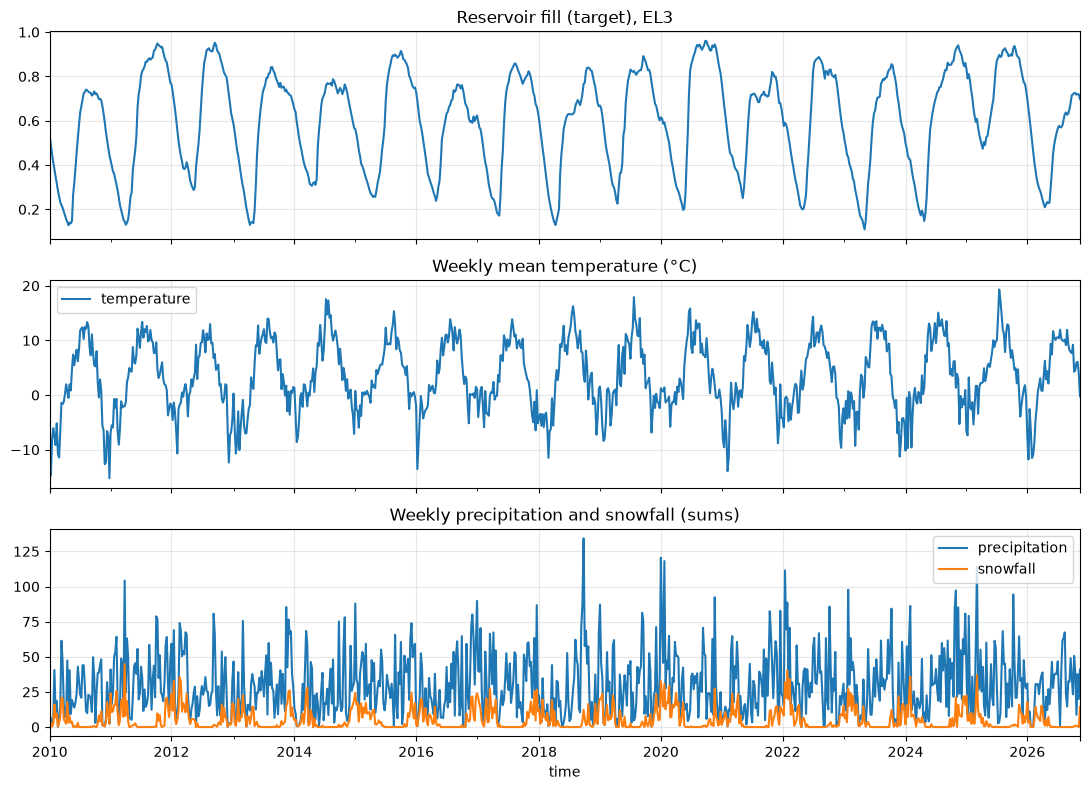

In [13]:
# ---- Load target and exogenous sources for one area -------------------------------------------
AREA_TYPE, AREA_NR = "EL", 3          # NO3, as in the earlier parts. Change freely (EL 1-5, VASS 1-3).
DATA_START = "2010-01-01"             # start of the weather/currency history (the target goes further back)

NVE_ANCHOR = detect_nve_anchor(nve)   # same value as in section 3.1
y_week = make_fill_series(nve, AREA_TYPE, AREA_NR, anchor=NVE_ANCHOR)
exog_week = build_exog_sources(AREA_TYPE, AREA_NR, start=DATA_START, anchor=NVE_ANCHOR)

print(f"Target {y_week.name}: {len(y_week)} weekly values, {y_week.index.min().date()} -> {y_week.index.max().date()}")
print("Value range (shows the unit, 0-1 or 0-100):", round(float(y_week.min()), 3), "-", round(float(y_week.max()), 3))
for name, df_ in exog_week.items():
    print(f"Exog '{name}': {df_.shape}, {df_.index.min().date()} -> {df_.index.max().date()}, "
          f"columns {list(df_.columns)}, NaN share {df_.isna().mean().mean():.3f}")

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
y_week.loc[DATA_START:].plot(ax=axes[0], title=f"Reservoir fill (target), {y_week.name}")
exog_week["weather"][["temperature"]].plot(ax=axes[1], title="Weekly mean temperature (°C)")
exog_week["weather"][["precipitation", "snowfall"]].plot(ax=axes[2], title="Weekly precipitation and snowfall (sums)")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 4.3 The forecast function

Structure of the code below

1. `build_exog_features` - lagged exogenous features for the training window **and** the future steps. Only data up to `train_end` is used; future weather is climatology, so there is **no leakage**.
2. `make_regressor` - builds the River regressor (linear model trained with SGD, or adaptive random forest).
3. `_run_snarimax` and `_run_lag_ml` - fit one model and return the forecast path (recursive / dynamic forecasting).
4. `forecast_fill` - the main function. Returns a `ForecastResult` with a forecast table (`forecast`, `lower`, `upper`).

**Parameters of `forecast_fill`**

| Group | Parameters |
|---|---|
| Data | `y`, `horizon`, `history` (number of recent steps used for training, `None` = all), `train_end`, `resolution` (`"W"`/`"M"`) |
| Model | `model` (`"snarimax"` or `"lag_ml"`) |
| SNARIMAX orders | `p, d, q` (non-seasonal), `sp, sd, sq` (seasonal, period `m`). Default `(3,0,1)(0,1,0)` = AR(3) + MA(1) after seasonal differencing |
| Lag-based ML | `lags`, `seasonal_terms`, `n_passes` (SNARIMAX learns in one pass because its lag buffer is part of the model state) |
| Regressor | `regressor` (`"linear"`/`"forest"`), `lr`, `l2`, `intercept_lr`, `n_trees` |
| Data sources | `exog` (dict), `exog_vars`, `exog_lags`, `future_rule` |
| Interval (bonus) | `interval`, `level` |

In [14]:
SEASON_LENGTH = {"W": 52, "M": 12}                         # seasonal period per resolution
DEFAULT_LAGS = {"W": (1, 2, 3, 4, 52), "M": (1, 2, 3, 12)}
DEFAULT_FUTURE_RULE = {"weather": "climatology", "currency": "last"}   # per exog source; others: 'last'


def to_resolution(obj, resolution: str):
    # Weekly data is returned unchanged; 'M' gives monthly means (month-end labels)
    if resolution == "W":
        return obj
    if resolution == "M":
        return obj.resample("ME").mean()
    raise ValueError("resolution must be 'W' or 'M'")


def _season_key(index: pd.DatetimeIndex, resolution: str) -> np.ndarray:
    # Week of year (1..52) or month (1..12): used for climatology and Fourier terms
    if resolution == "W":
        return np.minimum(index.isocalendar().week.to_numpy().astype(int), 52)
    return index.month.to_numpy()


def _fourier(index: pd.DatetimeIndex, resolution: str) -> list:
    # sin/cos seasonal terms (2 harmonics) as feature dicts, one per timestamp
    pos = _season_key(index, resolution) / SEASON_LENGTH[resolution]
    return [{"s1": np.sin(2 * np.pi * p), "c1": np.cos(2 * np.pi * p),
             "s2": np.sin(4 * np.pi * p), "c2": np.cos(4 * np.pi * p)} for p in pos]


def _future_values(known: pd.DataFrame, fut_index: pd.DatetimeIndex, rule: str, resolution: str) -> pd.DataFrame:
    # Values of an exogenous source for dates after the last known observation.
    #   'last'         : repeat the last known value
    #   'climatology'  : mean of the same week/month in all earlier years
    if rule == "last":
        return pd.DataFrame(np.tile(known.iloc[-1].to_numpy(), (len(fut_index), 1)),
                            index=fut_index, columns=known.columns)
    if rule == "climatology":
        clim = known.groupby(_season_key(known.index, resolution)).mean()
        vals = clim.reindex(_season_key(fut_index, resolution))
        vals.index = fut_index
        return vals.fillna(known.mean())                    # safety net for a week/month never seen
    raise ValueError("future_rule must be 'last' or 'climatology'")


def build_exog_features(exog: dict, exog_vars, exog_lags, hist_index, fut_index, train_end,
                        resolution="W", future_rule=None) -> pd.DataFrame:
    # Feature table (index = hist_index + fut_index) with one column per variable and lag.
    # Column names: 'temperature' (lag 0), 'temperature_lag4', ...
    # Values after `train_end` are never taken from the data, only from the rule (no leakage).
    rules = {**DEFAULT_FUTURE_RULE, **(future_rule or {})}
    all_index = hist_index.append(fut_index)
    wanted = {}                                            # source name -> list of columns
    for var in exog_vars:
        src = next((n for n, d in exog.items() if var in d.columns), None)
        if src is None:
            raise ValueError(f"Exogenous variable {var!r} not found. Available: "
                             f"{ {n: list(d.columns) for n, d in exog.items()} }")
        wanted.setdefault(src, []).append(var)

    pieces = []
    for src, cols in wanted.items():
        d = to_resolution(exog[src][cols], resolution).sort_index()
        known = d.loc[:train_end].dropna(how="any")
        if known.empty:
            raise ValueError(f"Source {src!r} has no data before train_end={train_end}")
        last_ok = known.index.max()                        # last real observation we may use
        ext = d.reindex(all_index)
        late = ext.index > last_ok                         # future AND not-yet-published days
        ext.loc[late] = _future_values(known, ext.index[late], rules.get(src, "last"), resolution).to_numpy()
        pieces.append(ext.interpolate(limit=4, limit_area="inside"))   # fill short internal holes
    base = pd.concat(pieces, axis=1)[list(exog_vars)]

    feats = {}
    for col in base.columns:
        for k in exog_lags:
            feats[col if k == 0 else f"{col}_lag{k}"] = base[col].shift(k)
    return pd.DataFrame(feats)


def make_regressor(kind="linear", lr=0.01, l2=0.0, intercept_lr=0.1, n_trees=10, seed=42, loss=None):
    # River regressor used by both models
    if kind == "linear":
        return preprocessing.StandardScaler() | linear_model.LinearRegression(
            optimizer=optim.SGD(lr), l2=l2, intercept_lr=intercept_lr,
            loss=loss if loss is not None else optim.losses.Squared())
    if kind == "forest":
        if loss is not None:
            raise ValueError("Quantile intervals need regressor='linear'")
        return forest.ARFRegressor(n_models=n_trees, seed=seed)
    raise ValueError("regressor must be 'linear' or 'forest'")

In [15]:
@dataclass
class ForecastResult:
    # Everything forecast_fill() returns
    forecast: pd.DataFrame          # index = forecast dates, columns forecast / lower / upper
    train_start: pd.Timestamp
    train_end: pd.Timestamp
    n_train: int
    model: str
    resolution: str
    settings: dict
    fit_seconds: float
    notes: list = field(default_factory=list)


def _run_snarimax(y_s, X_train, X_future, horizon, orders, regressor):
    # SNARIMAX (SARIMAX in River). One pass over the training data, then a dynamic multi-step forecast.
    model = time_series.SNARIMAX(regressor=regressor, **orders)
    for i, yi in enumerate(y_s):
        model.learn_one(yi, X_train[i] if X_train is not None else None)
    return np.asarray(model.forecast(horizon, xs=X_future), dtype=float)


def _run_lag_ml(y_s, X_train, X_future, fut_index, hist_index, resolution, lags, seasonal_terms,
                n_passes, regressor):
    # Lag-based ML: features = past values of y (+ exogenous + Fourier terms). Forecast is recursive:
    # each prediction is appended to the history and used as lag for the next step.
    max_lag = max(lags)
    four_h = _fourier(hist_index, resolution) if seasonal_terms else None
    four_f = _fourier(fut_index, resolution) if seasonal_terms else None

    def features(hist, i, x_exog, four):
        f = {f"y_lag{l}": hist[i - l] for l in lags}       # value l steps before position i
        if x_exog is not None:
            f.update(x_exog)
        if four is not None:
            f.update(four)
        return f

    for _ in range(n_passes):                               # several passes help the SGD models converge
        for i in range(max_lag, len(y_s)):
            regressor.learn_one(features(y_s, i, X_train[i] if X_train else None,
                                         four_h[i] if four_h else None), y_s[i])
    hist, out = list(y_s), []
    for h in range(len(fut_index)):
        pred = regressor.predict_one(features(hist, len(hist), X_future[h] if X_future else None,
                                              four_f[h] if four_f else None))
        hist.append(pred)
        out.append(pred)
    return np.asarray(out, dtype=float)

In [16]:
def forecast_fill(
    y: pd.Series,
    horizon: int = 26,
    history: int | None = 312,
    train_end=None,
    resolution: str = "W",
    model: str = "snarimax",
    # --- SNARIMAX orders: (p, d, q) non-seasonal, (sp, sd, sq) seasonal with period m
    # Default = SARIMA(3,0,1)(0,1,0)m: seasonal differencing (sd=1) removes the strong yearly cycle.
    # This is only a starting point; section 5 tests alternatives and the best one becomes the app default.
    p: int = 3, d: int = 0, q: int = 1, sp: int = 0, sd: int = 1, sq: int = 0, m: int | None = None,
    # --- lag-based ML
    lags: tuple | None = None, seasonal_terms: bool = True, n_passes: int = 3,
    # --- regressor settings (both models)
    regressor: str = "linear", lr: float = 0.01, l2: float = 0.0, intercept_lr: float = 0.1,
    n_trees: int = 10,
    # --- data sources
    exog: dict | None = None, exog_vars: tuple = (), exog_lags: tuple = (0,), future_rule: dict | None = None,
    # --- confidence interval (bonus): quantile regression
    interval: bool = False, level: float = 0.8,
    seed: int = 42,
) -> ForecastResult:
    # Forecast the next `horizon` steps of the fill of ONE area with River.
    #
    #  y          weekly fill series with a DatetimeIndex (see make_fill_series)
    #  horizon    number of steps ahead (weeks if resolution='W', months if 'M')
    #  history    number of most recent steps used for training (None = all)
    #  train_end  last date that may be used (default = end of y). Used for backtests.
    #  resolution 'W' (native) or 'M' (monthly means)
    #  model      'snarimax' | 'lag_ml'
    #  exog       {source: weekly DataFrame}; exog_vars picks columns, exog_lags the lags (in steps)
    #  future_rule  e.g. {'weather': 'climatology', 'currency': 'last'}
    #  interval   True -> also return `lower` and `upper` (quantile regression, level = 0.8 -> 10 %..90 %)
    t0 = time.perf_counter()
    notes = []

    # ---- 0. Input checks ------------------------------------------------------------------
    if horizon < 1:
        raise ValueError("horizon must be >= 1")
    if model not in ("snarimax", "lag_ml"):
        raise ValueError("model must be 'snarimax' or 'lag_ml'")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    if exog_vars and not exog:
        raise ValueError("exog_vars given but exog is empty")
    y = y.dropna().sort_index()
    if y.empty:
        raise ValueError("y has no data")
    m = m or SEASON_LENGTH[resolution]
    lags = tuple(lags) if lags else DEFAULT_LAGS[resolution]

    # ---- 1. Training window ----------------------------------------------------------------
    train_end = pd.Timestamp(train_end) if train_end is not None else y.index[-1]
    y_full = to_resolution(y.loc[:train_end], resolution)       # everything we are allowed to see
    y_tr = y_full.iloc[-history:] if history else y_full        # the part used for training
    freq = f"W-{y_tr.index[-1].day_name()[:3].upper()}" if resolution == "W" else "ME"
    fut_index = pd.date_range(y_tr.index[-1], periods=horizon + 1, freq=freq)[1:]

    # ---- 2. Exogenous features (training rows and future rows) -----------------------------------
    X_all = None
    if exog_vars:
        # Features are built over the FULL history so that the first training rows still have their lags
        X_all = build_exog_features(exog, exog_vars, exog_lags, y_full.index, fut_index,
                                    y_full.index[-1], resolution, future_rule)
        ok = X_all.loc[y_tr.index].notna().all(axis=1)      # rows where every lagged feature exists
        if not ok.any():
            raise ValueError("No training rows with complete exogenous data. Check exog dates and lags.")
        first_ok = ok[ok].index[0]
        if first_ok > y_tr.index[0]:
            notes.append(f"training start moved to {first_ok.date()} (exogenous data starts later)")
            y_tr = y_tr.loc[first_ok:]
        if X_all.loc[y_tr.index].isna().any().any() or X_all.loc[fut_index].isna().any().any():
            raise ValueError("The exogenous data has gaps inside the training window. "
                             "Use a shorter history or fill the gaps first.")
        X_train = X_all.loc[y_tr.index].to_dict("records")
        X_future = X_all.loc[fut_index].to_dict("records")
    else:
        X_train = X_future = None

    needed = max(lags) + 20 if model == "lag_ml" else m * max(sp + sd, 1) + p + q + 10
    if len(y_tr) < needed:
        raise ValueError(f"Only {len(y_tr)} training steps, but at least {needed} are needed for these settings. "
                         "Use a longer history or smaller orders/lags.")

    # ---- 3. Standardise the target ---------------------------------------------------------------
    mu, sd_y = float(y_tr.mean()), float(y_tr.std()) or 1.0
    y_s = ((y_tr - mu) / sd_y).to_numpy()
    orders = dict(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq)

    def run(loss=None):
        reg = make_regressor(regressor, lr, l2, intercept_lr, n_trees, seed, loss)
        if model == "snarimax":
            return _run_snarimax(y_s, X_train, X_future, horizon, orders, reg)
        return _run_lag_ml(y_s, X_train, X_future, fut_index, y_tr.index, resolution, lags,
                           seasonal_terms, n_passes, reg)

    # ---- 4. Fit and forecast ---------------------------------------------------------------------
    point = run()
    out = pd.DataFrame({"forecast": point * sd_y + mu}, index=fut_index)
    if interval:
        a = (1 - level) / 2
        out["lower"] = run(optim.losses.Quantile(a)) * sd_y + mu
        out["upper"] = run(optim.losses.Quantile(1 - a)) * sd_y + mu
        out["lower"] = np.minimum(out["lower"], out["forecast"])   # keep lower <= forecast <= upper
        out["upper"] = np.maximum(out["upper"], out["forecast"])
    else:
        out["lower"] = out["upper"] = np.nan

    # ---- 5. Keep values inside the physical range (fill is 0..1 or 0..100) -------------------------
    top = 1.0 if float(y.max()) <= 1.0 else 100.0
    out = out.clip(lower=0.0, upper=top)
    if not np.isfinite(out["forecast"]).all():
        notes.append("WARNING: the model diverged (NaN/inf). Lower the learning rate `lr`.")

    settings = dict(horizon=horizon, history=history, resolution=resolution, model=model, p=p, d=d, q=q, sp=sp,
                    sd=sd, sq=sq, m=m, lags=lags, seasonal_terms=seasonal_terms, n_passes=n_passes,
                    regressor=regressor, lr=lr, l2=l2, intercept_lr=intercept_lr, n_trees=n_trees,
                    exog_vars=tuple(exog_vars), exog_lags=tuple(exog_lags), interval=interval, level=level)
    return ForecastResult(out, y_tr.index[0], y_tr.index[-1], len(y_tr), model, resolution, settings,
                          time.perf_counter() - t0, notes)

### 4.4 Smoke test: does the function run, with and without exogenous data?

This is only a quick functional test (one forecast from the newest data). A proper evaluation with several settings, walk-forward backtests and a seasonal-naive benchmark follows in section 5.

,training steps,seconds,first forecast,last forecast,notes
SNARIMAX,312,0.016,0.669,0.061,-
SNARIMAX + weather,312,0.042,0.655,0.046,-
lag_ml + weather,312,0.108,0.694,0.319,-


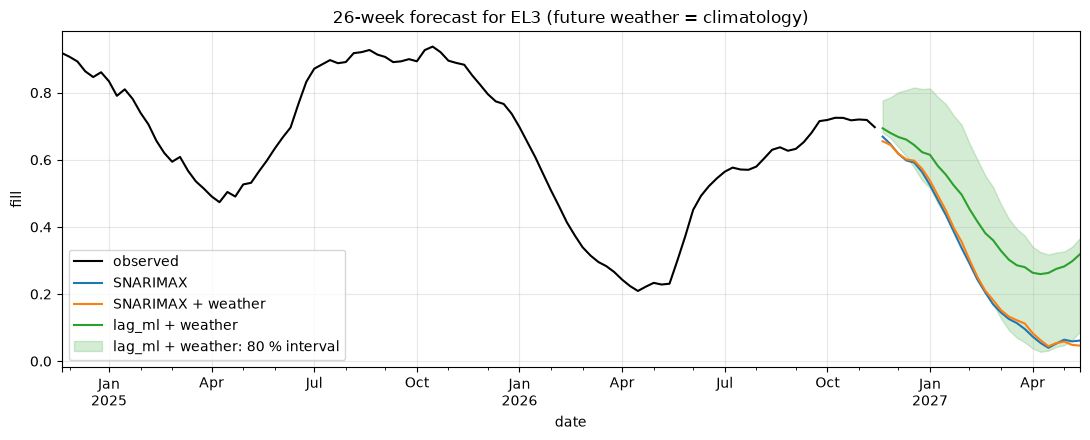

In [17]:
def plot_forecast(y, results: dict, last_n=104, title=None):
    # Plot the last `last_n` observed steps and one or more ForecastResult objects
    fig, ax = plt.subplots(figsize=(11, 4.5))
    y.iloc[-last_n:].plot(ax=ax, color="k", label="observed")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    for (name, r), c in zip(results.items(), colors):
        r.forecast["forecast"].plot(ax=ax, color=c, label=name)
        if r.forecast["lower"].notna().any():
            ax.fill_between(r.forecast.index, r.forecast["lower"], r.forecast["upper"], color=c, alpha=.2,
                            label=f"{name}: {int(r.settings['level'] * 100)} % interval")
    ax.set_title(title or f"Forecast of reservoir fill, {y.name}")
    ax.set_ylabel("fill")
    ax.legend()
    ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()


# Three variants: SNARIMAX alone, SNARIMAX + weather, lag-based ML + weather with an 80 % interval
runs = {
    "SNARIMAX": forecast_fill(y_week, horizon=26, history=312, model="snarimax"),
    "SNARIMAX + weather": forecast_fill(y_week, horizon=26, history=312, model="snarimax", exog=exog_week,
                                        exog_vars=("temperature", "precipitation", "snowfall"), exog_lags=(0, 4)),
    "lag_ml + weather": forecast_fill(y_week, horizon=26, history=312, model="lag_ml", exog=exog_week,
                                      exog_vars=("temperature", "snowfall"), exog_lags=(0, 4),
                                      interval=True, level=0.8),
}

summary = pd.DataFrame({
    name: {"training steps": r.n_train, "seconds": round(r.fit_seconds, 3),
           "first forecast": round(float(r.forecast["forecast"].iloc[0]), 3),
           "last forecast": round(float(r.forecast["forecast"].iloc[-1]), 3),
           "notes": "; ".join(r.notes) or "-"}
    for name, r in runs.items()
}).T
display(summary)
plot_forecast(y_week, runs, title=f"26-week forecast for {y_week.name} (future weather = climatology)")

### 4.5 Quick checks of the function itself

These cells check that the function reacts correctly to its inputs (they are not a quality test of the forecasts).

In [18]:
# 1) Forecast dates continue the weekly grid directly after the last training date
r = runs["SNARIMAX"]
assert r.forecast.index[0] == r.train_end + pd.Timedelta(days=7), "forecast does not start one week after the data"
assert (np.diff(r.forecast.index.values).astype("timedelta64[D]").astype(int) == 7).all()

# 2) train_end really hides later data (backtest use): same call, shorter data -> different forecast dates
r_old = forecast_fill(y_week, horizon=8, history=312, train_end=y_week.index[-60])
assert r_old.train_end == y_week.index[-60] and r_old.forecast.index[0] > y_week.index[-60]

# 3) Exogenous data after train_end must NOT change the result (no leakage)
exog_leak = {k: v.copy() for k, v in exog_week.items()}
exog_leak["weather"].loc[y_week.index[-59]:, "temperature"] += 50          # absurd values after train_end
a = forecast_fill(y_week, 8, 312, train_end=y_week.index[-60], exog=exog_week, exog_vars=("temperature",))
b = forecast_fill(y_week, 8, 312, train_end=y_week.index[-60], exog=exog_leak, exog_vars=("temperature",))
assert np.allclose(a.forecast["forecast"], b.forecast["forecast"]), "future exogenous data leaked into the forecast"

# 4) Readable errors for bad input
for bad in [dict(model="arima"), dict(horizon=0), dict(history=20), dict(exog_vars=("nonexistent",), exog=exog_week)]:
    try:
        forecast_fill(y_week, **{"horizon": 8, **bad})
        raise AssertionError(f"no error for {bad}")
    except ValueError as exc:
        print("OK, ValueError for", list(bad)[0], "->", str(exc)[:90])

# 5) Monthly resolution runs too (seasonal period 12)
r_m = forecast_fill(y_week, horizon=6, history=120, resolution="M")
print("\nMonthly forecast:", [str(d.date()) for d in r_m.forecast.index[:3]], "...", f"{r_m.fit_seconds:.3f} s")
print("All function checks passed.")

OK, ValueError for model -> model must be 'snarimax' or 'lag_ml'
OK, ValueError for horizon -> horizon must be >= 1
OK, ValueError for history -> Only 20 training steps, but at least 66 are needed for these settings. Use a longer histor
OK, ValueError for exog_vars -> Exogenous variable 'nonexistent' not found. Available: {'weather': ['temperature', 'precip

Monthly forecast: ['2026-12-31', '2027-01-31', '2027-02-28'] ... 0.013 s
All function checks passed.


## 5. Remaining items for this notebook

Done in this step: Norges Bank download (section 2), timezone investigation (section 3), River forecast function with SNARIMAX and lag-based ML, selectable parameters, history, horizon, data sources and optional quantile interval (section 4).

Next steps (in this order):

- [ ] **Test the forecast function for various settings** (walk-forward backtest, seasonal-naive benchmark, history length, orders, learning rate, exogenous sources, SNARIMAX vs lag-based ML, weekly vs monthly) and choose the default setting for Streamlit
- [ ] Move the forecast code to a module (e.g. `utils/forecasting.py`) so the Streamlit page and the notebook use the same functions
- [ ] Sliding-window correlation: findings from playing with lag and window length
- [ ] Sketch of the Streamlit page structure and navigation
- [ ] Brief description of AI usage
- [ ] 300-500-word log (Jupyter and Streamlit experience) and which bonus task was chosen
- [ ] Run all cells, export to PDF, commit `notebook_4.ipynb` to the `part-4` branch